In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

from sec_copilot.config import DATABASE_URL

# Where to save charts for the README (works whether the notebook runs from notebooks/ or the repo root).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHART_DIR = ROOT / "docs" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

engine = create_engine(DATABASE_URL)
df = pd.read_sql("SELECT * FROM v_quarterly_metrics", engine, parse_dates=["period_end"])

# The first years of XBRL data (2009-2013) have gaps, so we analyse 2014 onward.
df = df[df["period_end"] >= "2014-01-01"].sort_values(["ticker", "period_end"])

# Companies have different fiscal calendars, so we line them up by CALENDAR quarter.
# A fiscal quarter ends about 45 days after its midpoint, so (period_end - 45 days) falls in the
# calendar quarter that most of the fiscal quarter overlaps.
df["cal_quarter"] = (df["period_end"] - pd.Timedelta(days=45)).dt.to_period("Q")

print(df.shape)
print(df.dtypes[["revenue", "gross_margin_pct", "revenue_yoy_pct"]])

(740, 15)
revenue             float64
gross_margin_pct    float64
revenue_yoy_pct     float64
dtype: object


In [2]:
metrics = ["revenue", "gross_profit", "operating_income", "net_income"]
completeness = df.groupby("ticker")[metrics].count()
completeness["quarters"] = df.groupby("ticker").size()
completeness

,revenue,gross_profit,operating_income,net_income,quarters
ticker,,,,,
AAPL,50,50,50,50,50
ADBE,51,51,51,51,51
AMAT,51,51,51,51,51
AMD,50,50,50,50,50
AVGO,33,33,33,33,33
CRM,39,51,51,51,51
CSCO,51,51,51,51,51
IBM,50,50,0,50,50
INTC,50,50,50,50,50


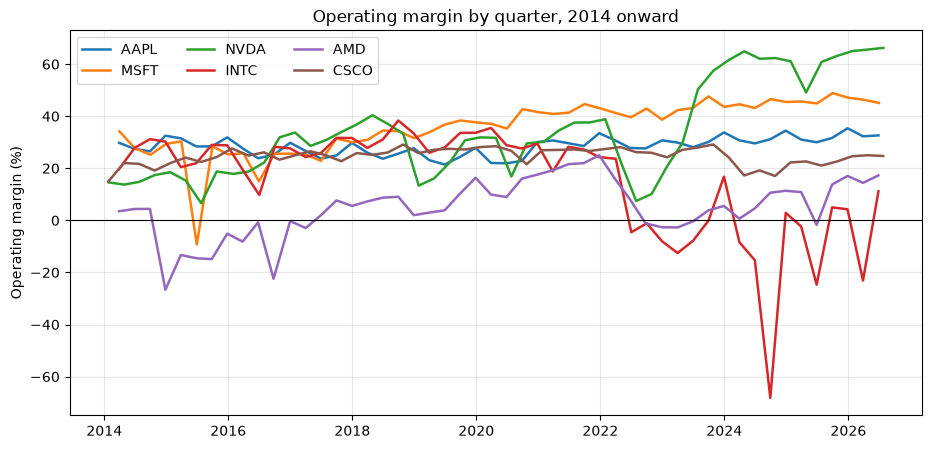

In [3]:
focus = ["AAPL", "MSFT", "NVDA", "INTC", "AMD", "CSCO"]
fig, ax = plt.subplots(figsize=(11, 5))
for ticker in focus:
    d = df[df["ticker"] == ticker]
    ax.plot(d["period_end"], d["operating_margin_pct"], label=ticker, linewidth=1.8)
ax.set_title("Operating margin by quarter, 2014 onward")
ax.set_ylabel("Operating margin (%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(alpha=0.3)
ax.legend(ncol=3)
fig.savefig(CHART_DIR / "operating_margin_trend.png", dpi=120, bbox_inches="tight")
plt.show()

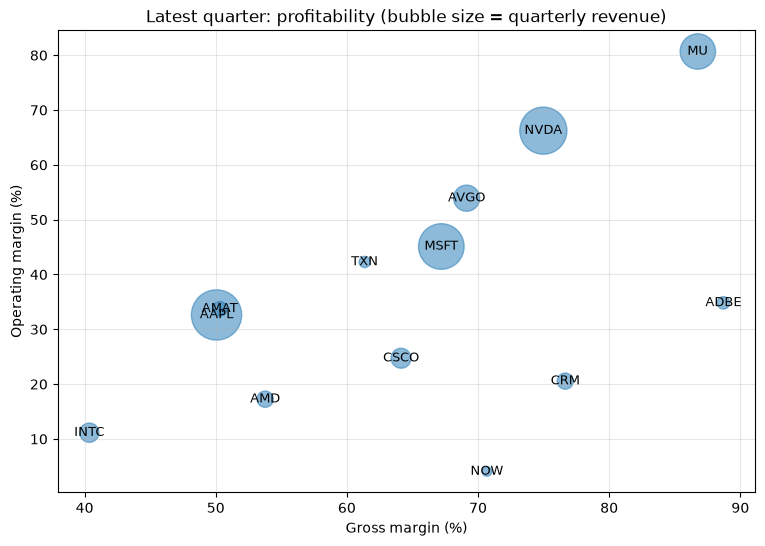

Left out (missing a metric): ['IBM', 'INTU']


In [4]:
latest = df.sort_values("period_end").groupby("ticker").tail(1)
plot_data = latest.dropna(subset=["gross_margin_pct", "operating_margin_pct", "revenue"])
left_out = sorted(set(latest["ticker"]) - set(plot_data["ticker"]))

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(plot_data["gross_margin_pct"], plot_data["operating_margin_pct"],
           s=plot_data["revenue"] / 1e9 * 12, alpha=0.5)
for _, row in plot_data.iterrows():
    ax.annotate(row["ticker"], (row["gross_margin_pct"], row["operating_margin_pct"]),
                ha="center", va="center", fontsize=9)
ax.set_xlabel("Gross margin (%)")
ax.set_ylabel("Operating margin (%)")
ax.set_title("Latest quarter: profitability (bubble size = quarterly revenue)")
ax.grid(alpha=0.3)
fig.savefig(CHART_DIR / "peer_profitability.png", dpi=120, bbox_inches="tight")
plt.show()
print("Left out (missing a metric):", left_out)

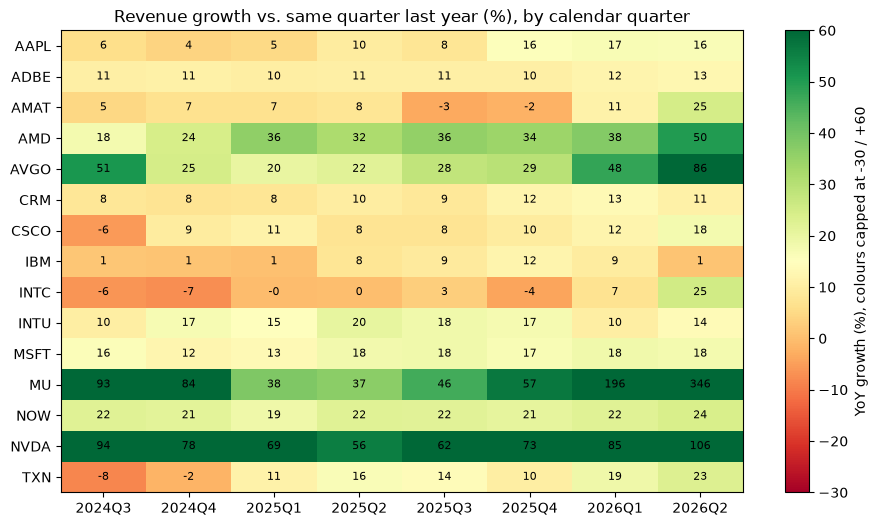

In [5]:
heat = df.pivot_table(index="ticker", columns="cal_quarter", values="revenue_yoy_pct", aggfunc="last")
heat = heat.loc[:, heat.notna().sum() >= 10].iloc[:, -8:]   # last 8 calendar quarters that most companies cover

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(heat.values, aspect="auto", cmap="RdYlGn", vmin=-30, vmax=60)
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels([str(c) for c in heat.columns])
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.values[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8)
ax.set_title("Revenue growth vs. same quarter last year (%), by calendar quarter")
fig.colorbar(im, label="YoY growth (%), colours capped at -30 / +60")
fig.savefig(CHART_DIR / "revenue_growth_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()